In [1]:
import numpy as np
# import ds_format as ds
import os
import glob
# import aquarius_time as aq
import xarray as xr
from scipy import interpolate
from netCDF4 import Dataset
from datetime import datetime
import pandas as pd
import time

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.ticker import MultipleLocator

In [2]:
data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
vdr_mask_data_dir = data_dir + '/CHCH_vdr_mask/processed{}'

### Opening data for one day

In [3]:
date = '20210518'
infile = vdr_mask_data_dir.format(date[:6]) + '/{}.nc'.format(date)
ds = xr.open_dataset(infile)

In [4]:
ds

<xarray.Dataset>
Dimensions:         (time: 288, level: 300, range: 300, bnds: 2)
Coordinates:
  * time            (time) datetime64[ns] 2021-05-18T00:02:29.999991 ... 2021...
Dimensions without coordinates: level, range, bnds
Data variables: (12/23)
    ICC_ij          (time, level) int32 ...
    ICC_j           (time) int32 ...
    LCC_ij          (time, level) int32 ...
    LCC_j           (time) int32 ...
    SLCC_ij         (time, level) int32 ...
    SLCC_j          (time) int32 ...
    ...              ...
    temp            (time, level) float64 ...
    time_bnds       (time, bnds) datetime64[ns] ...
    vdr             (time, level) float64 ...
    vdr_cm          (time, level) float64 ...
    vdr_threshold   float64 ...
    zfull           (level) float64 ...

### Plotting VDR cloud mask

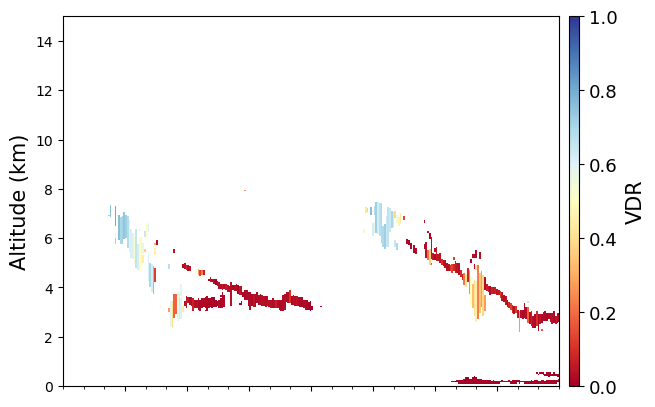

In [5]:
fig, ax2 = plt.subplots(1,1)
Im2=ax2.imshow(ds['vdr_cm'][:].T,             
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap='RdYlBu')
ax2.set_xticklabels([])
ax2.set_xticks(np.arange(36,288,36))
ax2.xaxis.set_minor_locator(MultipleLocator(12))
ax2.set_ylabel('Altitude (km)', fontsize=15)
cax2 = ax2.inset_axes([1.02,0,0.02,1],transform=ax2.transAxes)
fig.colorbar(Im2,
        extend='neither',
        cax=cax2,
    ).set_label(label='VDR', size=15, labelpad=6)
cax2.tick_params(labelsize=13)

### VDR distribution

(array([427., 611., 202.,  70.,  49.,  21.,  29.,  36.,  10.,   1.,  15.,
         37.,   8.,  58.,   0.,  20.,  62.,   5.,   2.,   1.,  20.,  33.,
         15.,  42.,  26.,  40.,  14.,  44.,  13.,   3.,  51.,  11.,  24.,
         10.,  26.,  52.,  27., 108., 101.,  61.,  70.,  30.,  33., 111.,
         92.,   0.,  54.,  27.,   0.,  16.]),
 array([0.00586543, 0.0218163 , 0.03776718, 0.05371806, 0.06966893,
        0.08561981, 0.10157069, 0.11752156, 0.13347244, 0.14942332,
        0.1653742 , 0.18132507, 0.19727595, 0.21322683, 0.2291777 ,
        0.24512858, 0.26107946, 0.27703033, 0.29298121, 0.30893209,
        0.32488297, 0.34083384, 0.35678472, 0.3727356 , 0.38868647,
        0.40463735, 0.42058823, 0.4365391 , 0.45248998, 0.46844086,
        0.48439174, 0.50034261, 0.51629349, 0.53224437, 0.54819524,
        0.56414612, 0.580097  , 0.59604787, 0.61199875, 0.62794963,
        0.6439005 , 0.65985138, 0.67580226, 0.69175314, 0.70770401,
        0.72365489, 0.73960577, 0.75555664, 0.

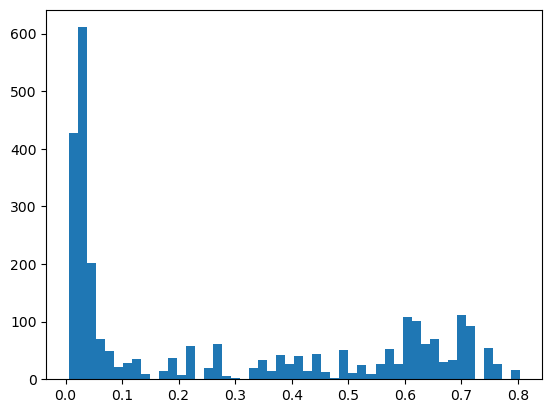

In [6]:
plt.hist(ds['vdr_cm'].values.flatten(), bins=50)

(array([ 427., 1038., 1240., 1310., 1359., 1380., 1409., 1445., 1455.,
        1456., 1471., 1508., 1516., 1574., 1574., 1594., 1656., 1661.,
        1663., 1664., 1684., 1717., 1732., 1774., 1800., 1840., 1854.,
        1898., 1911., 1914., 1965., 1976., 2000., 2010., 2036., 2088.,
        2115., 2223., 2324., 2385., 2455., 2485., 2518., 2629., 2721.,
        2721., 2775., 2802., 2802., 2818.]),
 array([0.00586543, 0.0218163 , 0.03776718, 0.05371806, 0.06966893,
        0.08561981, 0.10157069, 0.11752156, 0.13347244, 0.14942332,
        0.1653742 , 0.18132507, 0.19727595, 0.21322683, 0.2291777 ,
        0.24512858, 0.26107946, 0.27703033, 0.29298121, 0.30893209,
        0.32488297, 0.34083384, 0.35678472, 0.3727356 , 0.38868647,
        0.40463735, 0.42058823, 0.4365391 , 0.45248998, 0.46844086,
        0.48439174, 0.50034261, 0.51629349, 0.53224437, 0.54819524,
        0.56414612, 0.580097  , 0.59604787, 0.61199875, 0.62794963,
        0.6439005 , 0.65985138, 0.67580226, 0.69175314, 

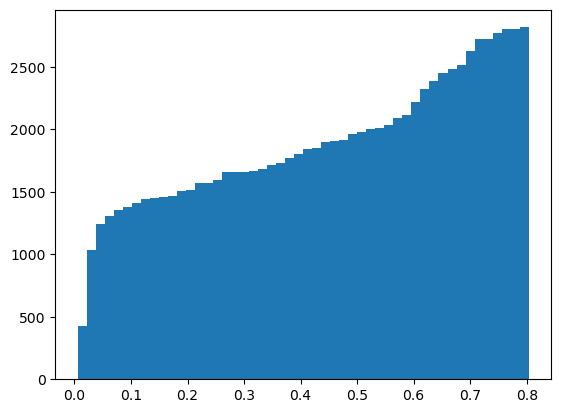

In [7]:
plt.hist(ds['vdr_cm'].values.flatten(), bins=50,cumulative=True)

In [8]:
np.nanmax(ds['vdr_cm'].values)

0.8034092745932351

### Filtering by temperature regime

In [26]:
clouds = ds.where(ds['cloud_mask'] == 1)

cold = clouds.where(clouds['temp'] < -40)
mixed = clouds.where((clouds['temp'] >= -40) & (clouds['temp'] <= 0))
warm = clouds.where(clouds['temp'] > 0)

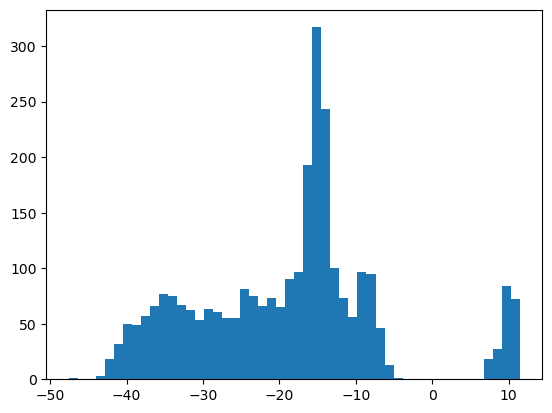

In [27]:
(_, temp_bins, _) = plt.hist(clouds['temp'].values.flatten(),bins=50)

(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0., 18., 27., 84., 72.]),
 array([-47.56739748, -46.38650352, -45.20560956, -44.0247156 ,
        -42.84382164, -41.66292768, -40.48203372, -39.30113976,
        -38.1202458 , -36.93935184, -35.75845788, -34.57756392,
        -33.39666996, -32.215776  , -31.03488204, -29.85398808,
        -28.67309412, -27.49220016, -26.3113062 , -25.13041223,
        -23.94951827, -22.76862431, -21.58773035, -20.40683639,
        -19.22594243, -18.04504847, -16.86415451, -15.68326055,
        -14.50236659, -13.32147263, -12.14057867, -10.95968471,
         -9.77879075,  -8.59789679,  -7.41700283,  -6.23610887,
         -5.05521491,  -3.87432095,  -2.69342699,  -1.51253303,
         -0.33163907,   0.84925489,   2.03014885,   3.21104281,
          4.

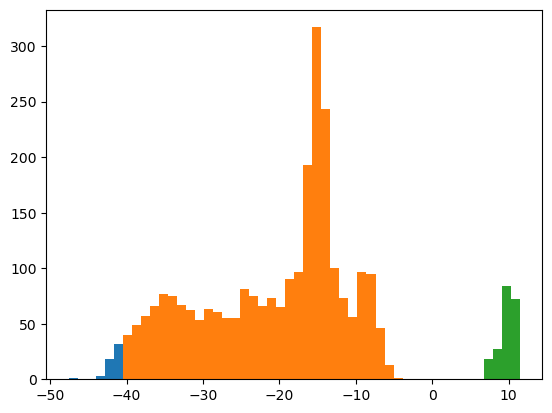

In [11]:
plt.hist(cold['temp'].values.flatten(), bins=temp_bins)
plt.hist(mixed['temp'].values.flatten(), bins=temp_bins)
plt.hist(warm['temp'].values.flatten(), bins=temp_bins)

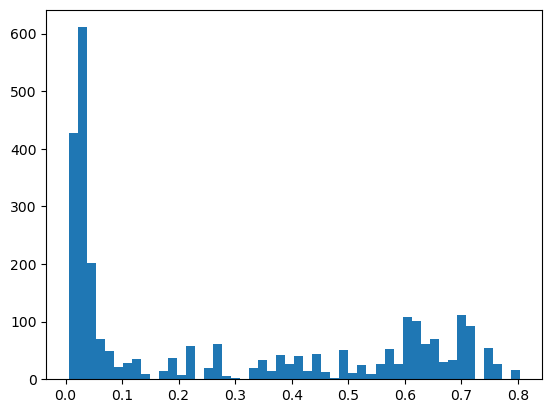

In [12]:
(_, vdr_bins, _) = plt.hist(ds['vdr_cm'].values.flatten(), bins=50)

(array([201.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.]),
 array([0.00586543, 0.0218163 , 0.03776718, 0.05371806, 0.06966893,
        0.08561981, 0.10157069, 0.11752156, 0.13347244, 0.14942332,
        0.1653742 , 0.18132507, 0.19727595, 0.21322683, 0.2291777 ,
        0.24512858, 0.26107946, 0.27703033, 0.29298121, 0.30893209,
        0.32488297, 0.34083384, 0.35678472, 0.3727356 , 0.38868647,
        0.40463735, 0.42058823, 0.4365391 , 0.45248998, 0.46844086,
        0.48439174, 0.50034261, 0.51629349, 0.53224437, 0.54819524,
        0.56414612, 0.580097  , 0.59604787, 0.61199875, 0.62794963,
        0.6439005 , 0.65985138, 0.67580226, 0.69175314, 0.70770401,
        0.72365489, 0.73960577, 0.75555664, 0.

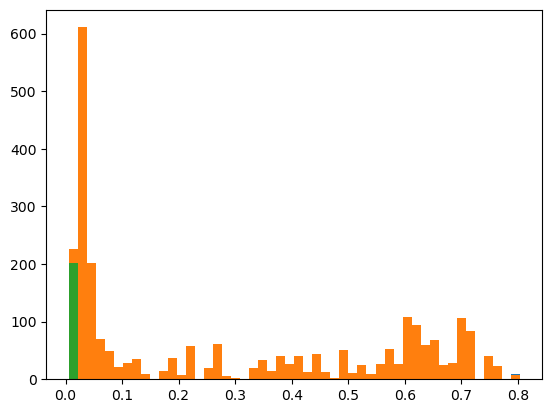

In [13]:
plt.hist(cold['vdr_cm'].values.flatten(), bins=vdr_bins)
plt.hist(mixed['vdr_cm'].values.flatten(), bins=vdr_bins)
plt.hist(warm['vdr_cm'].values.flatten(), bins=vdr_bins)

(array([201., 201., 201., 201., 201., 201., 201., 201., 201., 201., 201.,
        201., 201., 201., 201., 201., 201., 201., 201., 201., 201., 201.,
        201., 201., 201., 201., 201., 201., 201., 201., 201., 201., 201.,
        201., 201., 201., 201., 201., 201., 201., 201., 201., 201., 201.,
        201., 201., 201., 201., 201., 201.]),
 array([0.00586543, 0.0218163 , 0.03776718, 0.05371806, 0.06966893,
        0.08561981, 0.10157069, 0.11752156, 0.13347244, 0.14942332,
        0.1653742 , 0.18132507, 0.19727595, 0.21322683, 0.2291777 ,
        0.24512858, 0.26107946, 0.27703033, 0.29298121, 0.30893209,
        0.32488297, 0.34083384, 0.35678472, 0.3727356 , 0.38868647,
        0.40463735, 0.42058823, 0.4365391 , 0.45248998, 0.46844086,
        0.48439174, 0.50034261, 0.51629349, 0.53224437, 0.54819524,
        0.56414612, 0.580097  , 0.59604787, 0.61199875, 0.62794963,
        0.6439005 , 0.65985138, 0.67580226, 0.69175314, 0.70770401,
        0.72365489, 0.73960577, 0.75555664, 0.

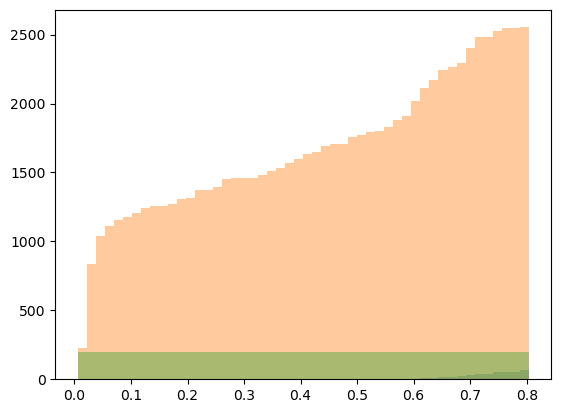

In [14]:
plt.hist(cold['vdr_cm'].values.flatten(), bins=vdr_bins,cumulative=True, alpha=0.4)
plt.hist(mixed['vdr_cm'].values.flatten(), bins=vdr_bins,cumulative=True, alpha=0.4)
plt.hist(warm['vdr_cm'].values.flatten(), bins=vdr_bins,cumulative=True, alpha=0.4)

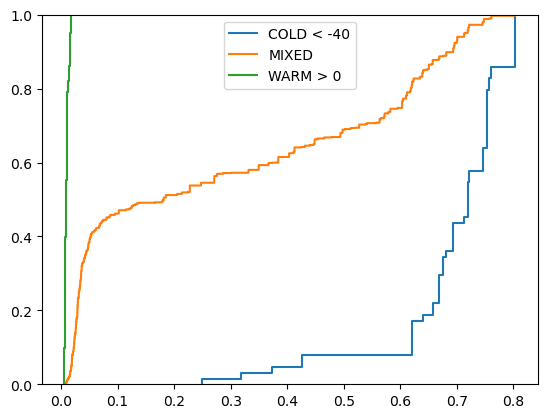

In [15]:
fig = plt.figure()
ax = fig.subplots(1, 1)

cold_vdr = cold['vdr_cm'].values.flatten()[~np.isnan(cold['vdr_cm'].values.flatten())]
mixed_vdr = mixed['vdr_cm'].values.flatten()[~np.isnan(mixed['vdr_cm'].values.flatten())]
warm_vdr = warm['vdr_cm'].values.flatten()[~np.isnan(warm['vdr_cm'].values.flatten())]

ax.ecdf(cold_vdr, label='COLD < -40')
ax.ecdf(mixed_vdr, label='MIXED')
ax.ecdf(warm_vdr, label='WARM > 0')
ax.legend()

### CDF plots by temperature bin

/home/lukeew/anaconda3/envs/00_Cloudsat_SO/lib/python3.10/site-packages/numpy/core/numeric.py:407: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


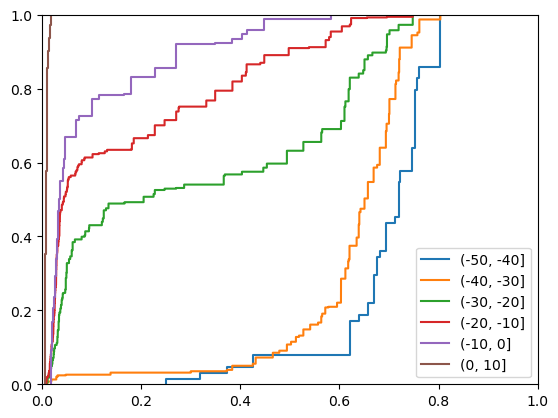

In [39]:
clouds = ds.where(ds['cloud_mask'] == 1)

temp_bins = [-50,-40,-30,-20,-10,0,10]

temps_gb = clouds.groupby_bins('temp', bins=temp_bins)

fig = plt.figure()
ax = fig.subplots(1, 1)

for (interval,group_ds) in temps_gb:
    vdr = group_ds['vdr_cm'].values.flatten()[~np.isnan(group_ds['vdr_cm'].values.flatten())]
    ax.ecdf(vdr, label=interval)

ax.legend()

ax.set_xlim(0,1)

plt.show()

## For larger subset

In [3]:
files = sorted(glob.glob(vdr_mask_data_dir.format('202105')+ '/*.nc'))

ds_list = [xr.open_dataset(infile) for infile in files[10:20]]

In [4]:
ds = xr.concat(ds_list, dim='time')
ds

<xarray.Dataset>
Dimensions:         (time: 2880, level: 300, range: 300, bnds: 2)
Coordinates:
  * time            (time) datetime64[ns] 2021-05-16T00:02:29.999991 ... 2021...
Dimensions without coordinates: level, range, bnds
Data variables: (12/23)
    ICC_ij          (time, level) int32 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    ICC_j           (time) int32 1 1 1 1 1 1 1 1 1 1 1 ... 0 0 0 0 0 0 0 0 0 0 0
    LCC_ij          (time, level) int32 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    LCC_j           (time) int32 0 0 0 0 0 0 1 1 1 1 1 ... 1 1 1 1 1 1 0 0 0 1 0
    SLCC_ij         (time, level) int32 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    SLCC_j          (time) int32 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    ...              ...
    temp            (time, level) float64 12.53 12.53 11.92 ... -59.48 -59.48
    time_bnds       (time, bnds) datetime64[ns] 2021-05-16 ... 2021-05-26
    vdr             (time, level) float64 -5.829 0.01705 ... 0.4025 3.396
    vdr_cm          (time, level) float64 nan nan nan nan ... nan nan nan nan
    vdr_threshold   (time) float64 0.1 0.1 0.1 0.1 0.1 ... 0.1 0.1 0.1 0.1 0.1
    zfull           (time, level) float64 25.0 75.0 ... 1.492e+04 1.498e+04

(array([4.860e+03, 2.237e+03, 5.840e+02, 2.960e+02, 2.000e+02, 1.090e+02,
        1.260e+02, 8.200e+01, 6.400e+01, 1.540e+02, 1.080e+02, 8.200e+01,
        1.140e+02, 9.300e+01, 8.700e+01, 1.060e+02, 7.300e+01, 1.000e+02,
        1.030e+02, 1.230e+02, 8.500e+01, 1.000e+02, 2.080e+02, 1.300e+02,
        2.460e+02, 3.140e+02, 2.480e+02, 2.040e+02, 3.580e+02, 4.120e+02,
        5.130e+02, 7.550e+02, 6.440e+02, 6.320e+02, 5.660e+02, 5.130e+02,
        3.880e+02, 4.420e+02, 2.900e+02, 9.700e+01, 1.520e+02, 6.400e+01,
        1.800e+01, 2.100e+01, 1.900e+01, 1.800e+01, 3.900e+01, 6.000e+00,
        1.000e+00, 3.000e+00]),
 array([0.00133932, 0.02114459, 0.04094985, 0.06075511, 0.08056037,
        0.10036564, 0.1201709 , 0.13997616, 0.15978143, 0.17958669,
        0.19939195, 0.21919722, 0.23900248, 0.25880774, 0.278613  ,
        0.29841827, 0.31822353, 0.33802879, 0.35783406, 0.37763932,
        0.39744458, 0.41724985, 0.43705511, 0.45686037, 0.47666563,
        0.4964709 , 0.51627616, 0.53

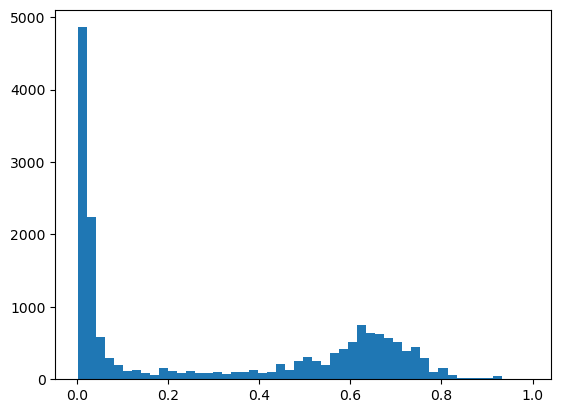

In [5]:
plt.hist(ds['vdr_cm'].values.flatten(), bins=50)

(array([ 4860.,  7097.,  7681.,  7977.,  8177.,  8286.,  8412.,  8494.,
         8558.,  8712.,  8820.,  8902.,  9016.,  9109.,  9196.,  9302.,
         9375.,  9475.,  9578.,  9701.,  9786.,  9886., 10094., 10224.,
        10470., 10784., 11032., 11236., 11594., 12006., 12519., 13274.,
        13918., 14550., 15116., 15629., 16017., 16459., 16749., 16846.,
        16998., 17062., 17080., 17101., 17120., 17138., 17177., 17183.,
        17184., 17187.]),
 array([0.00133932, 0.02114459, 0.04094985, 0.06075511, 0.08056037,
        0.10036564, 0.1201709 , 0.13997616, 0.15978143, 0.17958669,
        0.19939195, 0.21919722, 0.23900248, 0.25880774, 0.278613  ,
        0.29841827, 0.31822353, 0.33802879, 0.35783406, 0.37763932,
        0.39744458, 0.41724985, 0.43705511, 0.45686037, 0.47666563,
        0.4964709 , 0.51627616, 0.53608142, 0.55588669, 0.57569195,
        0.59549721, 0.61530248, 0.63510774, 0.654913  , 0.67471826,
        0.69452353, 0.71432879, 0.73413405, 0.75393932, 0.77374458

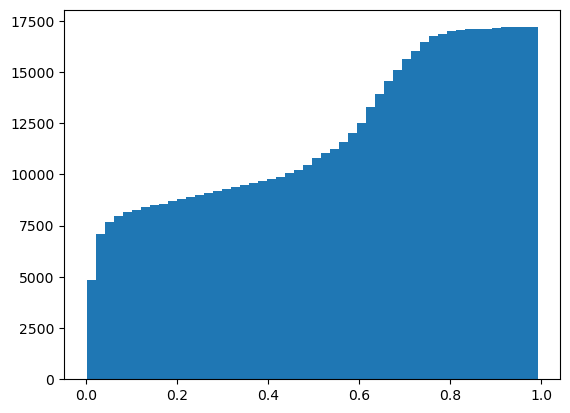

In [6]:
plt.hist(ds['vdr_cm'].values.flatten(), bins=50,cumulative=True)

In [7]:
np.nanmin(ds['vdr_cm'].values)

0.0013393227089913183

In [8]:
clouds = ds.where(ds['cloud_mask'] == 1)

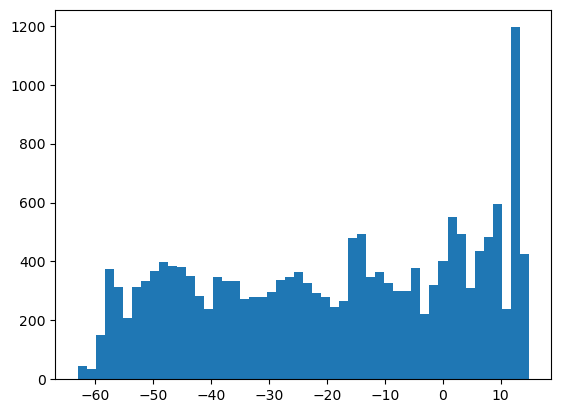

In [9]:
(_, temp_bins, _) = plt.hist(clouds['temp'].values.flatten(),bins=50)

In [11]:
# cold = clouds.where(clouds['temp'] < -40)
# mixed = clouds.where((clouds['temp'] >= -40) & (clouds['temp'] <= 0))
# warm = clouds.where(clouds['temp'] > 0)

: 

/home/lukeew/anaconda3/envs/00_Cloudsat_SO/lib/python3.10/site-packages/numpy/core/numeric.py:407: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


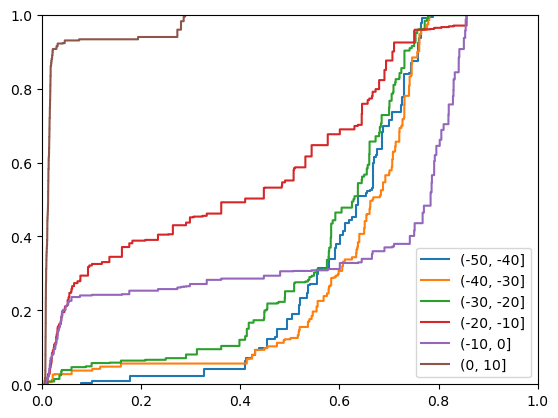

In [10]:
# temp_bins = [-50,-40,-30,-20,-10,0,10,20]

# temps_gb = clouds.groupby_bins('temp', bins=temp_bins)

# fig = plt.figure()
# ax = fig.subplots(1, 1)

# for (interval,group_ds) in temps_gb:
#     vdr = group_ds['vdr_cm'].values.flatten()[~np.isnan(group_ds['vdr_cm'].values.flatten())]
#     ax.ecdf(vdr, label=interval)

# ax.legend()

# ax.set_xlim(0,1)

# plt.show()

/home/lukeew/anaconda3/envs/00_Cloudsat_SO/lib/python3.10/site-packages/numpy/core/numeric.py:407: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


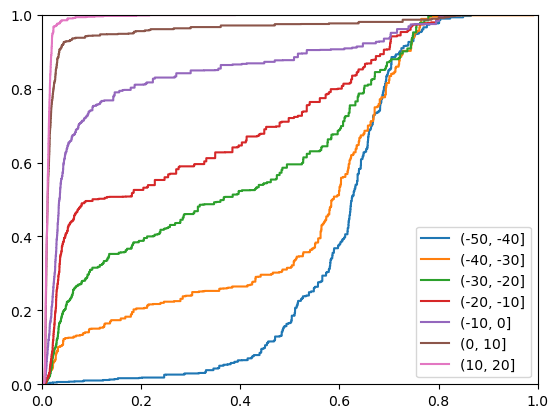

In [10]:
temp_bins = [-50,-40,-30,-20,-10,0,10,20]

temps_gb = clouds.groupby_bins('temp', bins=temp_bins)

fig = plt.figure()
ax = fig.subplots(1, 1)

for (interval,group_ds) in temps_gb:
    vdr = group_ds['vdr_cm'].values.flatten()[~np.isnan(group_ds['vdr_cm'].values.flatten())]
    ax.ecdf(vdr, label=interval)

ax.legend()

ax.set_xlim(0,1)

plt.show()